# 02 – Analysis

How much did knife prices fall after the supply shock of October 2025, and what explains the differences between knives?

The dependent variable is the log change of each knife's price between 22 and 24 October 2025. The explanatory variables describe the market of the knife (concentration, liquidity, share of western marketplaces) and the supply that could be converted into it: the stock and value of the covert guns and cases that lead to the same knife.

Input: `final.csv` from `01_data_collection.ipynb`.

In [1]:
import ast
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from tqdm import tqdm

## 1. Cleaning

In [2]:
df = pd.read_csv("final.csv") #Final dataset of the full run
df = df.loc[df["stpr"]>0] #Keep items with a positive price on 22 October
df = df.drop(columns=["API","stock","price"]) #Drop the listing-page price and stock, the API values are used instead
df["caseid"] = df["caseid"].apply(ast.literal_eval) #Case links: from string to list
df = df.loc[df["Souvenir"]==False] #Drop Souvenir items
df = df.drop(columns=["Souvenir"])
df["stattrak"] = df["stattrak"] == True #StatTrak flag as boolean
df

,case,url,name,type,cond,stattrak,west,HHI,liq,caseid,stpr,stst,enpr
0,knife,/cs2-items/skin/m9-bayonet-crimson-web/stattra...,Crimson Web,M9 Bayonet,Factory New,True,59.5,0.500000,0.01,[/cs2-skin-search/skin-cases/esports-2013-case...,7018430.0,1.0,7020500.0
4,knife,/cs2-items/skin/butterfly-knife-crimson-web/st...,Crimson Web,Butterfly Knife,Factory New,True,68.2,1.000000,0.22,[/cs2-skin-search/skin-cases/operation-breakou...,1086922.0,2.0,828250.0
6,knife,/cs2-items/skin/m9-bayonet-doppler-black-pearl...,Doppler - Black Pearl,M9 Bayonet,Factory New,True,56.7,0.500000,20.92,[/cs2-skin-search/skin-cases/chroma-case-skins...,1799900.0,4.0,631845.0
8,knife,/cs2-items/skin/butterfly-knife-doppler-black-...,Doppler - Black Pearl,Butterfly Knife,Factory New,True,55.9,0.500000,20.20,[/cs2-skin-search/skin-cases/spectrum-case-ski...,2276893.0,1.0,2808200.0
9,knife,/cs2-items/skin/butterfly-knife-gamma-doppler-...,Gamma Doppler - Emerald,Butterfly Knife,Minimal Wear,True,61.5,0.500000,17.61,[/cs2-skin-search/skin-cases/dreams-nightmares...,1754608.0,1.0,1112002.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4794,key,/cs2-items/key/case-key/operation-phoenix,Operation Phoenix Case Key,NaN,NaN,False,100.0,0.326531,9.03,[/cs2-skin-search/skin-cases/operation-bravo-c...,1092.0,180.0,1024.0
4795,key,/cs2-items/key/case-key/csgo,CS:GO Case Key,NaN,NaN,False,100.0,0.133270,9.86,[/cs2-skin-search/skin-cases/operation-bravo-c...,754.0,221.0,544.0
4796,key,/cs2-items/key/case-key/community-sticker-caps...,Community Sticker Capsule 1 Key,NaN,NaN,False,100.0,0.285714,5.43,[/cs2-skin-search/skin-cases/operation-bravo-c...,491.0,80.0,613.0
4797,key,/cs2-items/key/case-key/csgo-capsule-key,CS:GO Capsule Key,NaN,NaN,False,100.0,0.388430,5.26,[/cs2-skin-search/skin-cases/operation-bravo-c...,575.0,35.0,655.0


In [3]:
knifes = df.loc[df["case"]=="knife"].copy() #Knives
knifes = knifes.loc[knifes["enpr"]>0] #Keep knives with a positive price on 24 October
knifes["diff"] = np.log(knifes["enpr"]) - np.log(knifes["stpr"]) #Dependent variable: log price change between the two dates
knifes = knifes.reset_index(drop=True)
knifes

,case,url,name,type,cond,stattrak,west,HHI,liq,caseid,stpr,stst,enpr,diff
0,knife,/cs2-items/skin/m9-bayonet-crimson-web/stattra...,Crimson Web,M9 Bayonet,Factory New,True,59.5,0.5,0.01,[/cs2-skin-search/skin-cases/esports-2013-case...,7018430.0,1.0,7020500.0,0.000295
1,knife,/cs2-items/skin/butterfly-knife-crimson-web/st...,Crimson Web,Butterfly Knife,Factory New,True,68.2,1.0,0.22,[/cs2-skin-search/skin-cases/operation-breakou...,1086922.0,2.0,828250.0,-0.271790
2,knife,/cs2-items/skin/m9-bayonet-doppler-black-pearl...,Doppler - Black Pearl,M9 Bayonet,Factory New,True,56.7,0.5,20.92,[/cs2-skin-search/skin-cases/chroma-case-skins...,1799900.0,4.0,631845.0,-1.046842
3,knife,/cs2-items/skin/butterfly-knife-doppler-black-...,Doppler - Black Pearl,Butterfly Knife,Factory New,True,55.9,0.5,20.20,[/cs2-skin-search/skin-cases/spectrum-case-ski...,2276893.0,1.0,2808200.0,0.209732
4,knife,/cs2-items/skin/butterfly-knife-gamma-doppler-...,Gamma Doppler - Emerald,Butterfly Knife,Minimal Wear,True,61.5,0.5,17.61,[/cs2-skin-search/skin-cases/dreams-nightmares...,1754608.0,1.0,1112002.0,-0.456083
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3346,knife,/cs2-items/skin/stiletto-knife-boreal-forest/s...,Boreal Forest,Stiletto Knife,Factory New,True,95.5,0.0,0.03,[/cs2-skin-search/skin-cases/danger-zone-case-...,72512.0,1.0,40819.0,-0.574604
3347,knife,/cs2-items/skin/stiletto-knife-doppler-phase-4...,Doppler - Phase 4,Stiletto Knife,Minimal Wear,True,81.9,0.0,0.01,[/cs2-skin-search/skin-cases/prisma-case-skins...,98258.0,1.0,98287.0,0.000295
3348,knife,/cs2-items/skin/survival-knife-doppler-black-p...,Doppler - Black Pearl,Survival Knife,Factory New,True,100.0,1.0,1.01,[/cs2-skin-search/skin-cases/fever-case-skins],93570.0,1.0,93597.0,0.000289
3349,knife,/cs2-items/skin/skeleton-knife-doppler-sapphir...,Doppler - Sapphire,Skeleton Knife,Minimal Wear,True,76.8,0.5,0.01,[/cs2-skin-search/skin-cases/fever-case-skins],386014.0,1.0,1404165.0,1.291324


## 2. Convertible supply

For each knife: the stock and value of the covert guns (with the same StatTrak status) and of the cases that come from the same cases as the knife.

In [4]:
guns = df.loc[df["case"]=="gun"][["stattrak","caseid","stst","stpr"]].copy() #Covert guns
guns["val"] = guns["stst"]*guns["stpr"] #Total value of the gun's stock
guns = guns[["caseid","stattrak","stst","val"]]
guns = guns.reset_index(drop=True)

joiner = [] #Convertible gun stock and value per knife

for I in tqdm(range(len(knifes))): #Iterate through the knives
    STB = bool(knifes["stattrak"][I]) #StatTrak status of the knife
    subgun = guns.loc[[bool(set(knifes["caseid"][I]) & set(gun)) for gun in guns["caseid"]]] #Guns from at least one of the knife's cases
    subgun = subgun.loc[subgun["stattrak"]==STB] #with the same StatTrak status
    totstock = sum(subgun["stst"]) #Their total stock
    totval = sum(subgun["val"]) #Their total value
    joiner.append([str(knifes["url"][I]),totstock,totval])

joiner = pd.DataFrame(joiner,columns=["url","gun_stock","gun_val"])
analysis = knifes.join(joiner.set_index("url"),how="left",on="url") #Attach to the knives
analysis

100%|██████████| 3351/3351 [00:14<00:00, 224.35it/s]


,case,url,name,type,cond,stattrak,west,HHI,liq,caseid,stpr,stst,enpr,diff,gun_stock,gun_val
0,knife,/cs2-items/skin/m9-bayonet-crimson-web/stattra...,Crimson Web,M9 Bayonet,Factory New,True,59.5,0.5,0.01,[/cs2-skin-search/skin-cases/esports-2013-case...,7018430.0,1.0,7020500.0,0.000295,11104.0,326100013.0
1,knife,/cs2-items/skin/butterfly-knife-crimson-web/st...,Crimson Web,Butterfly Knife,Factory New,True,68.2,1.0,0.22,[/cs2-skin-search/skin-cases/operation-breakou...,1086922.0,2.0,828250.0,-0.271790,2617.0,25857417.0
2,knife,/cs2-items/skin/m9-bayonet-doppler-black-pearl...,Doppler - Black Pearl,M9 Bayonet,Factory New,True,56.7,0.5,20.92,[/cs2-skin-search/skin-cases/chroma-case-skins...,1799900.0,4.0,631845.0,-1.046842,9971.0,246918511.0
3,knife,/cs2-items/skin/butterfly-knife-doppler-black-...,Doppler - Black Pearl,Butterfly Knife,Factory New,True,55.9,0.5,20.20,[/cs2-skin-search/skin-cases/spectrum-case-ski...,2276893.0,1.0,2808200.0,0.209732,6270.0,100611149.0
4,knife,/cs2-items/skin/butterfly-knife-gamma-doppler-...,Gamma Doppler - Emerald,Butterfly Knife,Minimal Wear,True,61.5,0.5,17.61,[/cs2-skin-search/skin-cases/dreams-nightmares...,1754608.0,1.0,1112002.0,-0.456083,8721.0,61429029.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3346,knife,/cs2-items/skin/stiletto-knife-boreal-forest/s...,Boreal Forest,Stiletto Knife,Factory New,True,95.5,0.0,0.03,[/cs2-skin-search/skin-cases/danger-zone-case-...,72512.0,1.0,40819.0,-0.574604,7819.0,73358060.0
3347,knife,/cs2-items/skin/stiletto-knife-doppler-phase-4...,Doppler - Phase 4,Stiletto Knife,Minimal Wear,True,81.9,0.0,0.01,[/cs2-skin-search/skin-cases/prisma-case-skins...,98258.0,1.0,98287.0,0.000295,4754.0,39837889.0
3348,knife,/cs2-items/skin/survival-knife-doppler-black-p...,Doppler - Black Pearl,Survival Knife,Factory New,True,100.0,1.0,1.01,[/cs2-skin-search/skin-cases/fever-case-skins],93570.0,1.0,93597.0,0.000289,2824.0,39127542.0
3349,knife,/cs2-items/skin/skeleton-knife-doppler-sapphir...,Doppler - Sapphire,Skeleton Knife,Minimal Wear,True,76.8,0.5,0.01,[/cs2-skin-search/skin-cases/fever-case-skins],386014.0,1.0,1404165.0,1.291324,2824.0,39127542.0


In [5]:
case = df.loc[df["case"]=="case"][["url","stpr","stst"]].copy() #Cases
case = case.reset_index(drop=True)
case["val"] = case["stpr"]*case["stst"] #Total value of the case's stock
case = case.drop(columns=["stpr"])
case["url"] = case["url"] + "-skins" #Rewrite the case URL to the format used in the knives' case links
case["url"] =[urlurl.replace("/cs2-items/container","/cs2-skin-search/skin-cases") for urlurl in case["url"]]

joiner = [] #Convertible case stock and value per knife

for I in tqdm(range(len(knifes))): #Iterate through the knives
    subcase = case.loc[[str(cas) in knifes["caseid"][I] for cas in case["url"]]] #Cases the knife can be obtained from
    totval = sum(subcase["val"]) #Their total value
    totstock = sum(subcase["stst"]) #Their total stock
    joiner.append([str(knifes["url"][I]),totstock,totval])

joiner = pd.DataFrame(joiner,columns=["url","case_stock","case_val"])
analysis2 = analysis.join(joiner.set_index("url"),how="left",on="url") #Attach to the knives
analysis2

100%|██████████| 3351/3351 [00:01<00:00, 3301.55it/s]


,case,url,name,type,cond,stattrak,west,HHI,liq,caseid,stpr,stst,enpr,diff,gun_stock,gun_val,case_stock,case_val
0,knife,/cs2-items/skin/m9-bayonet-crimson-web/stattra...,Crimson Web,M9 Bayonet,Factory New,True,59.5,0.5,0.01,[/cs2-skin-search/skin-cases/esports-2013-case...,7018430.0,1.0,7020500.0,0.000295,11104.0,326100013.0,73925.0,92650884.0
1,knife,/cs2-items/skin/butterfly-knife-crimson-web/st...,Crimson Web,Butterfly Knife,Factory New,True,68.2,1.0,0.22,[/cs2-skin-search/skin-cases/operation-breakou...,1086922.0,2.0,828250.0,-0.271790,2617.0,25857417.0,64174.0,51660070.0
2,knife,/cs2-items/skin/m9-bayonet-doppler-black-pearl...,Doppler - Black Pearl,M9 Bayonet,Factory New,True,56.7,0.5,20.92,[/cs2-skin-search/skin-cases/chroma-case-skins...,1799900.0,4.0,631845.0,-1.046842,9971.0,246918511.0,135642.0,43876076.0
3,knife,/cs2-items/skin/butterfly-knife-doppler-black-...,Doppler - Black Pearl,Butterfly Knife,Factory New,True,55.9,0.5,20.20,[/cs2-skin-search/skin-cases/spectrum-case-ski...,2276893.0,1.0,2808200.0,0.209732,6270.0,100611149.0,160063.0,57647004.0
4,knife,/cs2-items/skin/butterfly-knife-gamma-doppler-...,Gamma Doppler - Emerald,Butterfly Knife,Minimal Wear,True,61.5,0.5,17.61,[/cs2-skin-search/skin-cases/dreams-nightmares...,1754608.0,1.0,1112002.0,-0.456083,8721.0,61429029.0,111547.0,28689713.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3346,knife,/cs2-items/skin/stiletto-knife-boreal-forest/s...,Boreal Forest,Stiletto Knife,Factory New,True,95.5,0.0,0.03,[/cs2-skin-search/skin-cases/danger-zone-case-...,72512.0,1.0,40819.0,-0.574604,7819.0,73358060.0,308745.0,44335359.0
3347,knife,/cs2-items/skin/stiletto-knife-doppler-phase-4...,Doppler - Phase 4,Stiletto Knife,Minimal Wear,True,81.9,0.0,0.01,[/cs2-skin-search/skin-cases/prisma-case-skins...,98258.0,1.0,98287.0,0.000295,4754.0,39837889.0,141056.0,18619392.0
3348,knife,/cs2-items/skin/survival-knife-doppler-black-p...,Doppler - Black Pearl,Survival Knife,Factory New,True,100.0,1.0,1.01,[/cs2-skin-search/skin-cases/fever-case-skins],93570.0,1.0,93597.0,0.000289,2824.0,39127542.0,473317.0,60584576.0
3349,knife,/cs2-items/skin/skeleton-knife-doppler-sapphir...,Doppler - Sapphire,Skeleton Knife,Minimal Wear,True,76.8,0.5,0.01,[/cs2-skin-search/skin-cases/fever-case-skins],386014.0,1.0,1404165.0,1.291324,2824.0,39127542.0,473317.0,60584576.0


In [6]:
analysis3 = analysis2.copy()
analysis3["gun_relstock"] = analysis3["gun_stock"]/analysis3["stst"] #Convertible gun stock relative to the knife's own stock
analysis3["gun_meanval"] = analysis3["gun_val"]/analysis3["gun_stock"] #Mean value of the convertible guns
analysis3["gun_relval"] = analysis3["gun_meanval"]/analysis3["stpr"] #relative to the knife's price

analysis3["case_relstock"] = analysis3["case_stock"]/analysis3["stst"] #Case stock relative to the knife's own stock
analysis3["case_meanval"] = analysis3["case_val"]/analysis3["case_stock"] #Mean value of the cases
analysis3["case_relval"] = analysis3["case_meanval"]/analysis3["stpr"] #relative to the knife's price

analysis3 = analysis3.loc[analysis3["stst"]>100] #Keep knives with more than 100 items in stock on 22 October

regdf = analysis3[["diff","west","HHI","liq","gun_relstock","gun_relval","case_relstock","case_relval"]].copy() #Regression variables
regdf = regdf.dropna()

for var in regdf.columns[1:]:
    regdf = regdf.loc[regdf[var]>=0] #Drop negative values, which can only come from data errors

regdf["west"] = regdf["west"]/100 #Share of western marketplaces, 0-1
regdf["liq"] = regdf["liq"]/100 #Liquidity, 0-1

regdf

,diff,west,HHI,liq,gun_relstock,gun_relval,case_relstock,case_relval
87,-1.466163,0.990,0.301587,0.5623,170.027523,0.011908,1244.422018,0.000665
88,-1.252159,0.393,0.148789,0.5509,4.304046,0.013944,37.094798,0.001744
94,-0.900832,0.521,0.138483,0.5250,142.842932,0.010887,584.015707,0.000633
97,-1.089914,0.377,0.159722,0.4968,73.722772,0.015496,635.386139,0.001938
103,-1.176427,0.534,0.144531,0.3591,12.765854,0.024273,313.043902,0.001978
...,...,...,...,...,...,...,...,...
3332,-0.809981,0.829,0.148126,0.7208,16.531884,0.802479,102.214493,0.017287
3333,-0.645620,0.939,0.150884,0.6350,41.909370,0.550935,171.347158,0.032018
3334,-0.707192,0.887,0.155556,0.5850,54.566000,0.541432,223.094000,0.031465
3335,-0.774139,0.854,0.116343,0.7767,36.088624,0.547392,147.548942,0.031812


## 3. Functional form

In [7]:
expl_vars = regdf.columns[1:].tolist() #Candidate explanatory variables

y = regdf["diff"] #Dependent variable
X = regdf[expl_vars].copy()
X["const"] = 1

spec_model = sm.OLS(y, X).fit() #Linear baseline

sm.stats.diagnostic.linear_reset(spec_model) #Ramsey RESET test
#p < 0.05: the linear form is misspecified

<class 'statsmodels.stats.contrast.ContrastResults'>
<Wald test (chi2): statistic=48.1644657482773, p-value=3.4771157713200665e-11, df_denom=2>

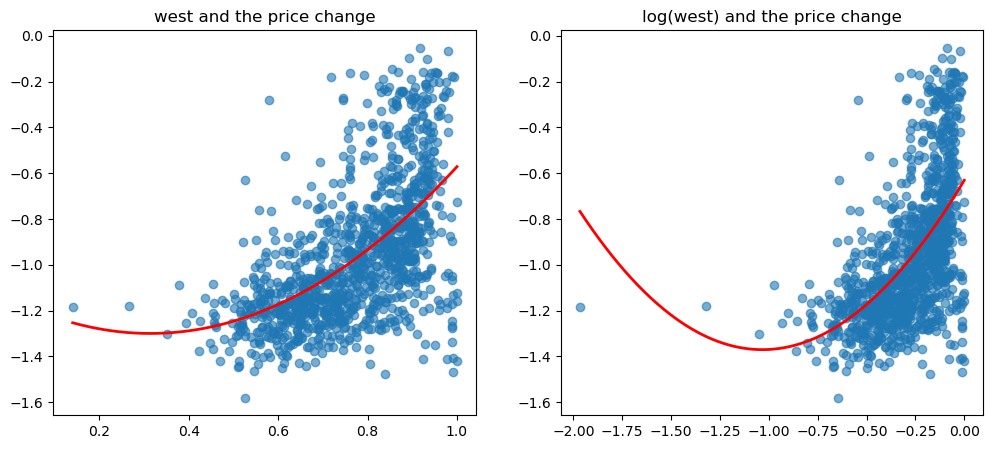

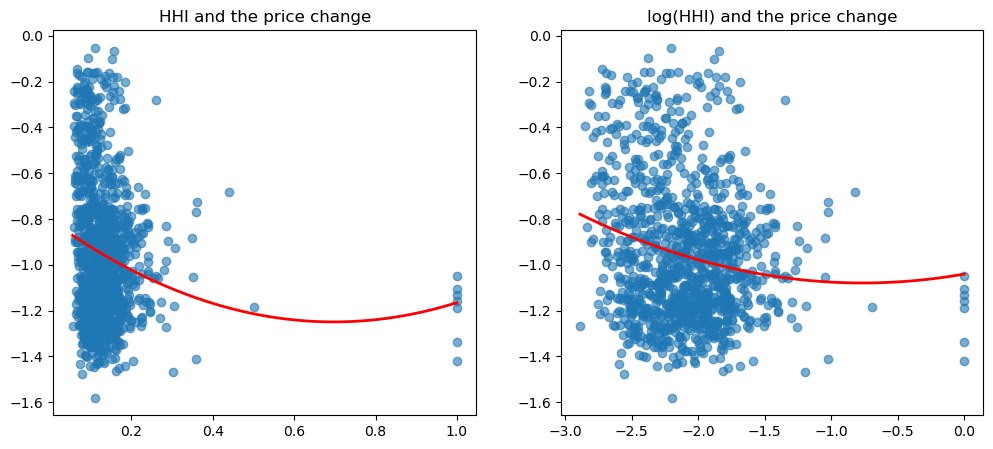

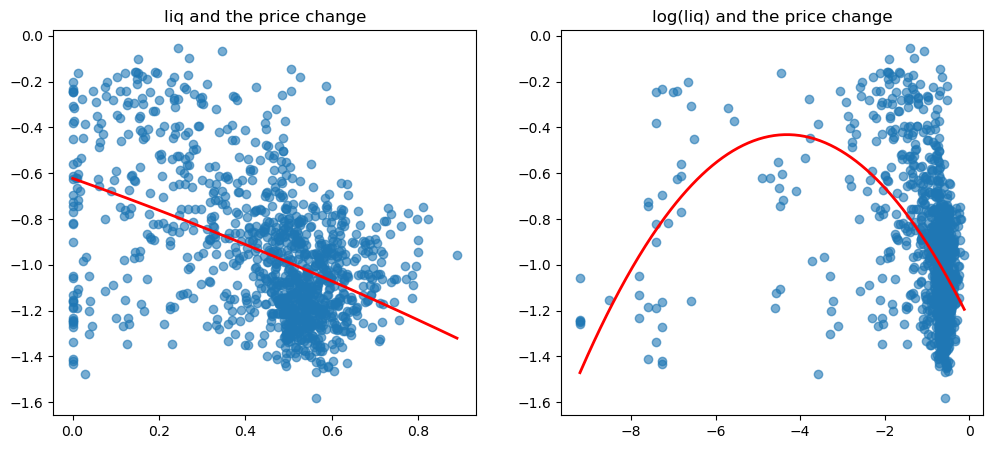

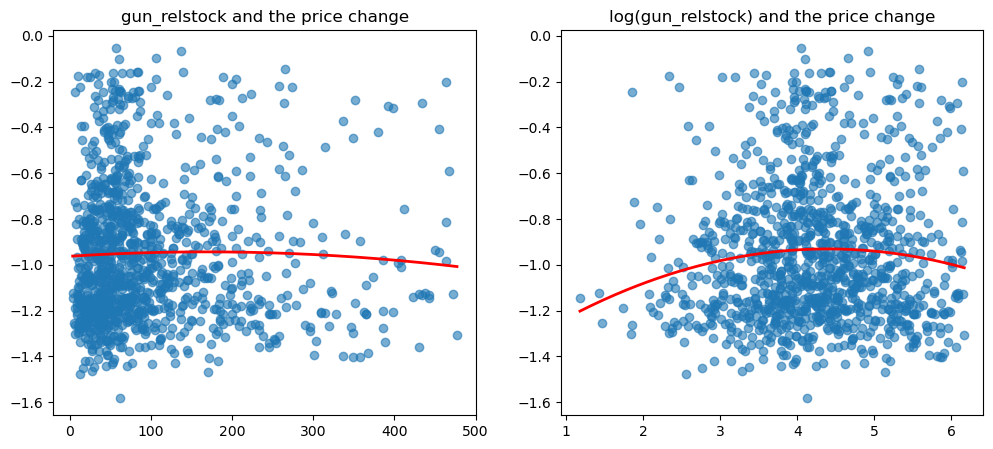

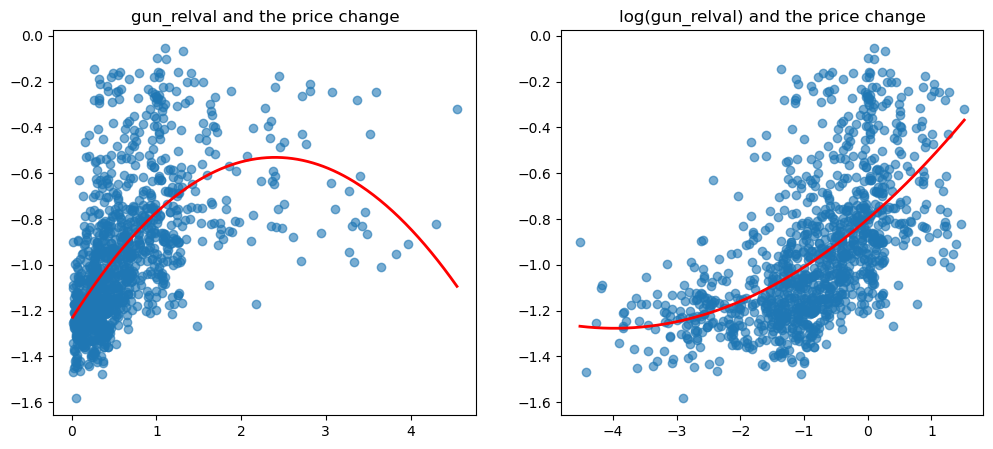

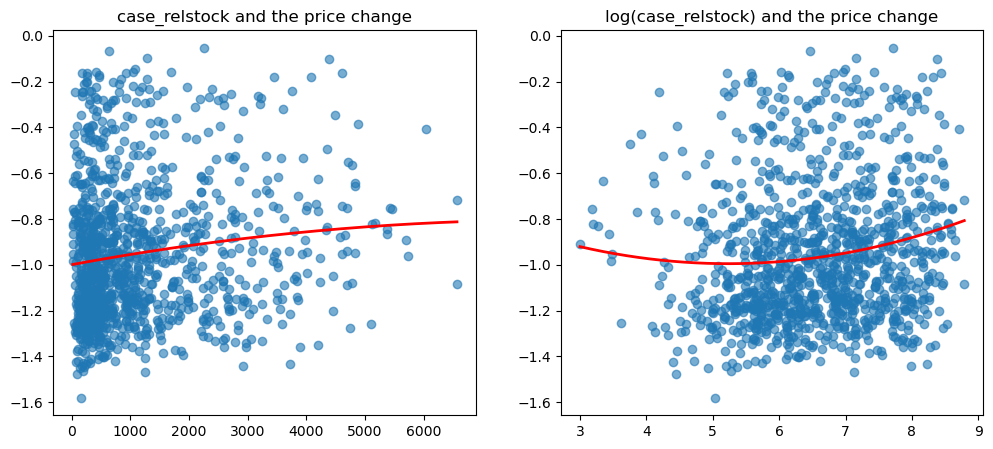

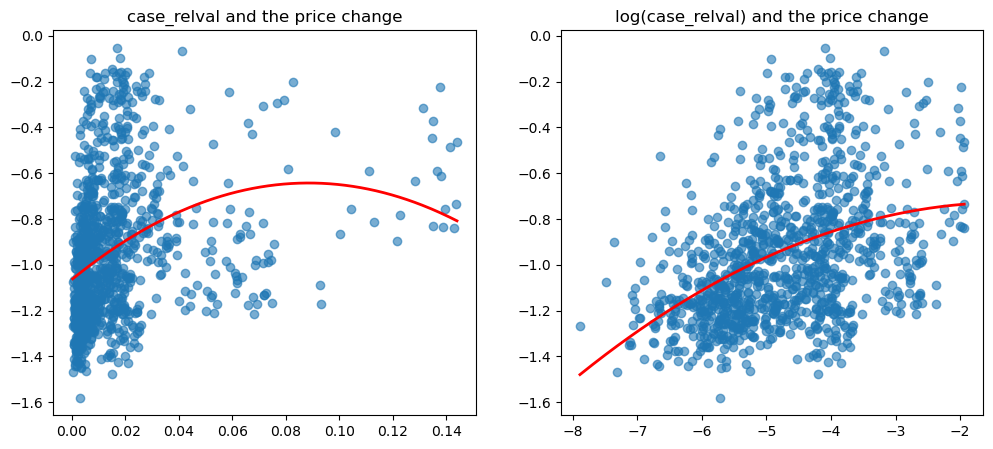

In [8]:
for var in expl_vars: #Scatter plot of each variable against the price change, in levels and in logs
    x = X[var]
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].scatter(x, y, alpha=0.6)
    coef1 = np.polyfit(x, y, 2) #Quadratic trend line
    poly1 = np.poly1d(coef1)
    xx1 = np.linspace(x.min(), x.max(), 300)
    axes[0].plot(xx1, poly1(xx1), color='red', linewidth=2)
    axes[0].set_title(f"{var} and the price change")

    coef2 = np.polyfit(np.log(x), y, 2) #Quadratic trend line on the log scale
    poly2 = np.poly1d(coef2)
    xx2 = np.linspace(np.log(x).min(), np.log(x).max(), 300)
    axes[1].scatter(np.log(x), y, alpha=0.6)
    axes[1].plot(xx2, poly2(xx2), color='red', linewidth=2)
    axes[1].set_title(f"log({var}) and the price change")

plt.show()

In [9]:
regdf["west2"] = regdf["west"]**2 #Square of the western share
regdf["sqrt_gun_relval"] = np.sqrt(regdf["gun_relval"]) #Square root of the relative gun value
regdf["log_case_relstock"] = np.log(regdf["case_relstock"]) #Log of the relative case stock
regdf["log_case_relval"] = np.log(regdf["case_relval"]) #Log of the relative case value

regdf = regdf.drop(columns=["west","gun_relval","case_relstock","case_relval"]) #Keep the transformed versions
main_effects = regdf.columns[1:].tolist() #The seven main effects
regdf

,diff,HHI,liq,gun_relstock,west2,sqrt_gun_relval,log_case_relstock,log_case_relval
87,-1.466163,0.301587,0.5623,170.027523,0.980100,0.109122,7.126426,-7.316236
88,-1.252159,0.148789,0.5509,4.304046,0.154449,0.118087,3.613477,-6.351707
94,-0.900832,0.138483,0.5250,142.842932,0.271441,0.104341,6.369928,-7.365509
97,-1.089914,0.159722,0.4968,73.722772,0.142129,0.124484,6.454233,-6.246181
103,-1.176427,0.144531,0.3591,12.765854,0.285156,0.155799,5.746343,-6.225861
...,...,...,...,...,...,...,...,...
3332,-0.809981,0.148126,0.7208,16.531884,0.687241,0.895812,4.627073,-4.057827
3333,-0.645620,0.150884,0.6350,41.909370,0.881721,0.742250,5.143692,-3.441465
3334,-0.707192,0.155556,0.5850,54.566000,0.786769,0.735821,5.407593,-3.458866
3335,-0.774139,0.116343,0.7767,36.088624,0.729316,0.739859,4.994160,-3.447918


## 4. Interaction screening

Exploratory step: every pairwise product of the main effects is ranked by its correlation with the price change, and the five strongest are added to the model. Because the interactions are chosen by looking at the outcome, the p-values of the later models are not valid for formal inference.

In [10]:
pairs = list(itertools.combinations(main_effects, 2)) #All pairs of main effects

intercor = [] #Correlation of each product with the price change

for pair in pairs:
    intercor.append([pair[0]+"_x_"+pair[1], np.corrcoef(regdf[pair[0]]*regdf[pair[1]],regdf["diff"])[0][1]])

intercor = pd.DataFrame(intercor,columns=["interaction","corcoef"])
intercor["corcoef"] = np.abs(intercor["corcoef"]) #Strength of the correlation
intercor = intercor.sort_values("corcoef",ascending=False)
intercor = intercor[0:5] #Five strongest
intercor

,interaction,corcoef
15,west2_x_sqrt_gun_relval,0.648446
18,sqrt_gun_relval_x_log_case_relstock,0.593579
16,west2_x_log_case_relstock,0.548531
10,liq_x_log_case_relval,0.533421
19,sqrt_gun_relval_x_log_case_relval,0.472579


In [11]:
for Int in intercor["interaction"]: #Add the five interactions to the data
    comp = str(Int).split("_x_")
    regdf[str(Int)] = regdf[comp[0]]*regdf[comp[1]]

regdf

,diff,HHI,liq,gun_relstock,west2,sqrt_gun_relval,log_case_relstock,log_case_relval,west2_x_sqrt_gun_relval,sqrt_gun_relval_x_log_case_relstock,west2_x_log_case_relstock,liq_x_log_case_relval,sqrt_gun_relval_x_log_case_relval
87,-1.466163,0.301587,0.5623,170.027523,0.980100,0.109122,7.126426,-7.316236,0.106950,0.777647,6.984611,-4.113920,-0.798359
88,-1.252159,0.148789,0.5509,4.304046,0.154449,0.118087,3.613477,-6.351707,0.018238,0.426703,0.558098,-3.499155,-0.750051
94,-0.900832,0.138483,0.5250,142.842932,0.271441,0.104341,6.369928,-7.365509,0.028322,0.664645,1.729060,-3.866892,-0.768525
97,-1.089914,0.159722,0.4968,73.722772,0.142129,0.124484,6.454233,-6.246181,0.017693,0.803451,0.917334,-3.103103,-0.777552
103,-1.176427,0.144531,0.3591,12.765854,0.285156,0.155799,5.746343,-6.225861,0.044427,0.895274,1.638604,-2.235707,-0.969982
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3332,-0.809981,0.148126,0.7208,16.531884,0.687241,0.895812,4.627073,-4.057827,0.615639,4.144989,3.179915,-2.924882,-3.635051
3333,-0.645620,0.150884,0.6350,41.909370,0.881721,0.742250,5.143692,-3.441465,0.654458,3.817906,4.535301,-2.185331,-2.554429
3334,-0.707192,0.155556,0.5850,54.566000,0.786769,0.735821,5.407593,-3.458866,0.578921,3.979018,4.254527,-2.023436,-2.545105
3335,-0.774139,0.116343,0.7767,36.088624,0.729316,0.739859,4.994160,-3.447918,0.539591,3.694976,3.642321,-2.677998,-2.550975


## 5. Models

In [12]:
y = regdf["diff"]

X1 = regdf[main_effects].copy() #Model 1: main effects only
X1["const"] = 1
model1 = sm.OLS(y, X1).fit()
print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:                   diff   R-squared:                       0.531
Model:                            OLS   Adj. R-squared:                  0.528
Method:                 Least Squares   F-statistic:                     181.4
Date:                Thu, 15 Oct 2026   Prob (F-statistic):          1.96e-179
Time:                        16:11:03   Log-Likelihood:                 169.60
No. Observations:                1129   AIC:                            -323.2
Df Residuals:                    1121   BIC:                            -283.0
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
HHI                  -0.5771      0.07

In [13]:
X2 = regdf[regdf.columns[1:]].copy() #Model 2: main effects and the five interactions
X2["const"] = 1
model2 = sm.OLS(y, X2).fit()
print(model2.summary())

print(sm.stats.diagnostic.het_white(model2.resid,X2)) #White test for heteroscedasticity
#p < 0.05: heteroscedastic errors, so robust standard errors are used below

model2_r = sm.OLS(y, X2).fit(cov_type='HC0') #Model 2 with heteroscedasticity-robust (HC0) standard errors
print(model2_r.summary())

                            OLS Regression Results                            
Dep. Variable:                   diff   R-squared:                       0.559
Model:                            OLS   Adj. R-squared:                  0.554
Method:                 Least Squares   F-statistic:                     118.0
Date:                Thu, 15 Oct 2026   Prob (F-statistic):          7.84e-189
Time:                        16:11:03   Log-Likelihood:                 204.45
No. Observations:                1129   AIC:                            -382.9
Df Residuals:                    1116   BIC:                            -317.5
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                                          coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
HH

In [14]:
keep = [var for var in model2_r.pvalues.index if model2_r.pvalues[var]<0.05 and var!="const"] #Terms significant at 5% in robust model 2

X3 = regdf[keep].copy() #Model 3: only those terms
X3["const"] = 1
model3 = sm.OLS(y, X3).fit(cov_type='HC0') #with robust standard errors
print(model3.summary())

                            OLS Regression Results                            
Dep. Variable:                   diff   R-squared:                       0.559
Model:                            OLS   Adj. R-squared:                  0.555
Method:                 Least Squares   F-statistic:                     143.0
Date:                Thu, 15 Oct 2026   Prob (F-statistic):          3.59e-179
Time:                        16:11:03   Log-Likelihood:                 203.71
No. Observations:                1129   AIC:                            -387.4
Df Residuals:                    1119   BIC:                            -337.1
Df Model:                           9                                         
Covariance Type:                  HC0                                         
                                          coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
HH

## 6. Model comparison

The F-test of nested models assumes the classical covariance matrix, so it is run on the non-robust fits.

In [15]:
def WALDFTEST(full,restr): #F-test of a restricted model against a fuller one
    F_stat, p_value, df_diff = full.compare_f_test(restr)
    print("F-statistic:", F_stat)
    print("p-value:", p_value)
    print("df_diff:", df_diff)

model3_ols = sm.OLS(y, X3).fit() #Non-robust fit of model 3, for the F-test

WALDFTEST(model2,model1) #Model 1 vs model 2: do the interactions add explanatory power?
#p < 0.05: the interactions improve the fit, model 2 is preferred to model 1

WALDFTEST(model2,model3_ols) #Model 3 vs model 2: do the dropped terms matter?
#p > 0.05: the dropped terms add nothing significant, model 3 is preferred as it uses fewer parameters

F-statistic: 14.210948604181766
p-value: 1.673288495573661e-13
df_diff: 5.0
F-statistic: 0.4832388148578875
p-value: 0.6939913495063963
df_diff: 3.0


In [16]:
sm.stats.diagnostic.linear_reset(model3,power=3) #RESET test of the final model
#Still p < 0.05, but the statistic is lower than for the linear baseline: the specification improved but is not fully correct

<class 'statsmodels.stats.contrast.ContrastResults'>
<Wald test (chi2): statistic=41.243512018489, p-value=1.1068407960398916e-09, df_denom=2>